In [67]:
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image, ImageOps
import pytesseract

pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)

In [68]:
def load_csv(path):
    for enc in ("utf-8", "utf-8-sig", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc, low_memory=False)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Could not read {path}")

FDC_PATH    = glob.glob("India_Prohibited_FDC_Combinations*.csv")[0]
banned_df   = load_csv("India_Banned_Drugs_Final.csv")
medicine_df = load_csv("India_Medicine_Master_253973_FULL.csv")
fdc_df      = load_csv(FDC_PATH)

for name, df in [("BANNED", banned_df), ("MEDICINE", medicine_df), ("FDC", fdc_df)]:
    print(f"\n===== {name} {df.shape} =====")
    print(df.columns.tolist())
    display(df.head(3))
    print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
    print("Exact duplicate rows:", df.duplicated().sum())


===== BANNED (681, 14) =====
['Ban_ID', 'Ban_Category', 'Drug_or_Combination', 'Ingredients_Normalized', 'Applies_To', 'Is_Current_Per_Dataset', 'Ban_Reason', 'Notification_Number', 'Notification_Date', 'Regulatory_Authority', 'Source_URL', 'Source_Check_Status', 'Medicines_In_Master_Count', 'Matched_Medicine_Names']


,Ban_ID,Ban_Category,Drug_or_Combination,Ingredients_Normalized,Applies_To,Is_Current_Per_Dataset,Ban_Reason,Notification_Number,Notification_Date,Regulatory_Authority,Source_URL,Source_Check_Status,Medicines_In_Master_Count,Matched_Medicine_Names
0,FDC-2023-2394,CURRENT_FDC_PROHIBITED,Nimesulide + Paracetamol Dispersible Tablets,nimesulide + paracetamol,HUMAN,Yes,Prohibited by the Central Government under Section 26A for manufacture for s...,S.O.2394 (E),2023-06-02,Ministry of Health and Family Welfare / CDSCO,https://www.cdsco.gov.in/opencms/opencms/en/Notifications/Gazette-Notificati...,Label in source file says verified; not independently checked against CDSCO,0,NaN
1,FDC-2023-2395,CURRENT_FDC_PROHIBITED,Amoxicillin + Bromhexine,amoxicillin + bromhexine,HUMAN,Yes,Prohibited by the Central Government under Section 26A for manufacture for s...,S.O.2395 (E),2023-06-02,Ministry of Health and Family Welfare / CDSCO,https://www.cdsco.gov.in/opencms/opencms/en/Notifications/Gazette-Notificati...,Label in source file says verified; not independently checked against CDSCO,0,NaN
2,FDC-2023-2396,CURRENT_FDC_PROHIBITED,Pholcodine + Promethazine,pholcodine + promethazine,HUMAN,Yes,Prohibited by the Central Government under Section 26A for manufacture for s...,S.O.2396 (E),2023-06-02,Ministry of Health and Family Welfare / CDSCO,https://www.cdsco.gov.in/opencms/opencms/en/Notifications/Gazette-Notificati...,Label in source file says verified; not independently checked against CDSCO,0,NaN


Missing values:
 Ingredients_Normalized     41
Matched_Medicine_Names    671
dtype: int64
Exact duplicate rows: 0

===== MEDICINE (253968, 24) =====
['Medicine_ID', 'Medicine_Name', 'Generic_Name', 'Ingredient_1', 'Ingredient_2', 'Ingredient_3', 'Strength', 'Dosage_Form', 'Therapeutic_Category', 'Manufacturer', 'Pack_Size', 'Price_INR', 'Is_Discontinued', 'Country', 'Age_Group', 'Restriction_Status', 'Restriction_Type', 'Restriction_Reason', 'Regulatory_Authority', 'Notification_Number', 'Source', 'Source_URL', 'Verification_Status', 'Source_ID']


,Medicine_ID,Medicine_Name,Generic_Name,Ingredient_1,Ingredient_2,Ingredient_3,Strength,Dosage_Form,Therapeutic_Category,Manufacturer,Pack_Size,Price_INR,Is_Discontinued,Country,Age_Group,Restriction_Status,Restriction_Type,Restriction_Reason,Regulatory_Authority,Notification_Number,Source,Source_URL,Verification_Status,Source_ID
0,INDMED_FULL_000001,Augmentin 625 Duo Tablet,Amoxycillin,Amoxycillin (500mg),Clavulanic Acid (125mg),NaN,500mg,Tablet,NaN,Glaxo SmithKline Pharmaceuticals Ltd,strip of 10 tablets,223.42,False,India,NaN,NOT_YET_REGULATORY_VERIFIED,NaN,NaN,NaN,NaN,"Indian Medicine Dataset — 253,973 product catalog",https://github.com/junioralive/Indian-Medicine-Dataset,PUBLIC_DATASET_SOURCE_NOT_CDSCO_VERIFIED,1
1,INDMED_FULL_000002,Azithral 500 Tablet,Azithromycin,Azithromycin (500mg),NaN,NaN,500mg,Tablet,NaN,Alembic Pharmaceuticals Ltd,strip of 5 tablets,132.36,False,India,NaN,NOT_YET_REGULATORY_VERIFIED,NaN,NaN,NaN,NaN,"Indian Medicine Dataset — 253,973 product catalog",https://github.com/junioralive/Indian-Medicine-Dataset,PUBLIC_DATASET_SOURCE_NOT_CDSCO_VERIFIED,2
2,INDMED_FULL_000003,Ascoril LS Syrup,Ambroxol,Ambroxol (30mg/5ml),Levosalbutamol (1mg/5ml),NaN,30mg/5ml,Syrup,NaN,Glenmark Pharmaceuticals Ltd,bottle of 100 ml Syrup,118.00,False,India,NaN,NOT_YET_REGULATORY_VERIFIED,NaN,NaN,NaN,NaN,"Indian Medicine Dataset — 253,973 product catalog",https://github.com/junioralive/Indian-Medicine-Dataset,PUBLIC_DATASET_SOURCE_NOT_CDSCO_VERIFIED,3


Missing values:
 Ingredient_2            141799
Ingredient_3            253968
Strength                  3947
Dosage_Form               2637
Therapeutic_Category    253968
Age_Group               253968
Restriction_Type        253968
Restriction_Reason      253968
Regulatory_Authority    253968
Notification_Number     253968
dtype: int64
Exact duplicate rows: 0

===== FDC (187, 19) =====
['Combination_ID', 'Combination_Key', 'Ingredient_Count', 'Ingredient_1', 'Ingredient_2', 'Ingredient_3', 'Ingredient_4', 'Full_Combination', 'Regulatory_Category', 'Restriction_Status', 'Restriction_Type', 'Reason', 'Notification_Number', 'Notification_Date', 'Regulatory_Authority', 'Country', 'Verification_Status', 'Source_URL', 'Original_Restriction_Text']


,Combination_ID,Combination_Key,Ingredient_Count,Ingredient_1,Ingredient_2,Ingredient_3,Ingredient_4,Full_Combination,Regulatory_Category,Restriction_Status,Restriction_Type,Reason,Notification_Number,Notification_Date,Regulatory_Authority,Country,Verification_Status,Source_URL,Original_Restriction_Text
0,IND-FDC-P-0001,amylase+protease+glucoamylase+pectinase+alpha+galactosidase+lactase+beta+glu...,4,Amylase,Protease,Glucoamylase,Pectinase,Amylase + Protease + Glucoamylase + Pectinase + Alpha Galactosidase + Lactas...,PROHIBITED_FDC,PROHIBITED,PROHIBITION_UNDER_SECTION_26A,No therapeutic justification; the FDC may involve risk to human beings.,S.O. 3285(E),2024-08-12,"Central Government, Ministry of Health & Family Welfare",India,VERIFIED_OFFICIAL_CDSCO_SOURCE,https://www.cdsco.gov.in/opencms/opencms/en/Drugs/FDC/,NaN
1,IND-FDC-P-0002,antimony+potassium+tartrate+dried+ferrous+sulphate,2,Antimony Potassium Tartrate,Dried Ferrous Sulphate,NaN,NaN,Antimony Potassium Tartrate + Dried Ferrous Sulphate,PROHIBITED_FDC,PROHIBITED,PROHIBITION_UNDER_SECTION_26A,No therapeutic justification; the FDC may involve risk to human beings.,S.O. 3286(E),2024-08-12,"Central Government, Ministry of Health & Family Welfare",India,VERIFIED_OFFICIAL_CDSCO_SOURCE,https://www.cdsco.gov.in/opencms/opencms/en/Drugs/FDC/,NaN
2,IND-FDC-P-0003,benfotiamine+silymarin+l+ornithine+l+aspartate+sodium+selenite+folic+acid+py...,4,Benfotiamine,Silymarin,L-Ornithine L-aspartate,Sodium Selenite,Benfotiamine + Silymarin + L-Ornithine L-aspartate + Sodium Selenite + Folic...,PROHIBITED_FDC,PROHIBITED,PROHIBITION_UNDER_SECTION_26A,No therapeutic justification; the FDC may involve risk to human beings.,S.O. 3287(E),2024-08-12,"Central Government, Ministry of Health & Family Welfare",India,VERIFIED_OFFICIAL_CDSCO_SOURCE,https://www.cdsco.gov.in/opencms/opencms/en/Drugs/FDC/,NaN


Missing values:
 Ingredient_3                  59
Ingredient_4                 109
Original_Restriction_Text    187
dtype: int64
Exact duplicate rows: 0


In [69]:
print(medicine_df["Restriction_Status"].value_counts(dropna=False).head())

reg = medicine_df[medicine_df["Restriction_Type"].notna()]
print("\nRows with restriction info:", len(reg))
display(reg[["Medicine_Name", "Restriction_Status", "Restriction_Type", "Notification_Number"]])

print("\nFDC rows by ingredient count:")
print(fdc_df["Ingredient_Count"].value_counts().sort_index())

Restriction_Status
NOT_YET_REGULATORY_VERIFIED    253968
Name: count, dtype: int64

Rows with restriction info: 0


,Medicine_Name,Restriction_Status,Restriction_Type,Notification_Number



FDC rows by ingredient count:
Ingredient_Count
2    59
3    50
4    78
Name: count, dtype: int64


In [70]:
def find_col(df, *keywords):
    for c in df.columns:
        if any(k in c.lower() for k in keywords):
            return c
    return None

MED_NAME = "Medicine_Name"
MED_ING  = find_col(medicine_df, "ingredient", "composition", "generic")
BAN_COL  = find_col(banned_df, "drug", "generic", "name", "ingredient")
FDC_COL  = find_col(fdc_df, "fdc", "combination", "drug", "name", "ingredient")

print("Master name       :", MED_NAME)
print("Master ingredients:", MED_ING)
print("Banned column     :", BAN_COL)
print("FDC column        :", FDC_COL)
# If any is None or wrong, set it by hand, e.g. BAN_COL = "Drug_Name"

Master name       : Medicine_Name
Master ingredients: Generic_Name
Banned column     : Drug_or_Combination
FDC column        : Combination_ID


In [71]:
PLACEHOLDERS = {"", "na", "n/a", "nan", "null", "none", "-", "--", "nil", "unknown"}

def clean_value(x):
    if pd.isna(x):
        return np.nan
    x = re.sub(r"\s+", " ", str(x)).strip()
    return np.nan if x.lower() in PLACEHOLDERS else x

def normalize(text):
    text = str(text).lower()
    text = re.sub(r"\(.*?\)", " ", text)
    text = re.sub(r"\b\d+(\.\d+)?\s*(mg|mcg|gm|g|ml|iu|%)\b", " ", text)
    text = re.sub(r"\b(ip|bp|usp|hcl|tablets?|capsules?|syrup|injection)\b", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def split_ingredients(text):
    if pd.isna(text):
        return []
    parts = re.split(r"\+|,|;|/|\band\b", str(text), flags=re.I)
    return sorted({normalize(p) for p in parts if normalize(p)})

def names_match(a, b):
    """Whole-word match in either direction."""
    if not a or not b:
        return False
    return a == b or re.search(rf"\b{re.escape(a)}\b", b) is not None \
                  or re.search(rf"\b{re.escape(b)}\b", a) is not None

# 1) Clean text columns, then drop exact duplicates
for df in (banned_df, medicine_df, fdc_df):
    for c in [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]:
        df[c] = df[c].apply(clean_value)
    df.drop_duplicates(inplace=True)
    df.reset_index(drop=True, inplace=True)

# 2) Normalized columns used by the checks
medicine_df["ingredients_list"] = medicine_df[MED_ING].apply(split_ingredients)
medicine_df["n_ingredients"]    = medicine_df["ingredients_list"].apply(len)
medicine_df["ingredient_missing"] = medicine_df["n_ingredients"] == 0   # flagged, never guessed

banned_df["drug_norm"]       = banned_df[BAN_COL].apply(normalize)
fdc_df["fdc_ingredients"]    = fdc_df[FDC_COL].apply(split_ingredients)

print("Master rows:", len(medicine_df), "| no ingredient info:", medicine_df["ingredient_missing"].sum())
print("Banned rows:", len(banned_df), "| FDC rows:", len(fdc_df))

Master rows: 253968 | no ingredient info: 0
Banned rows: 681 | FDC rows: 187


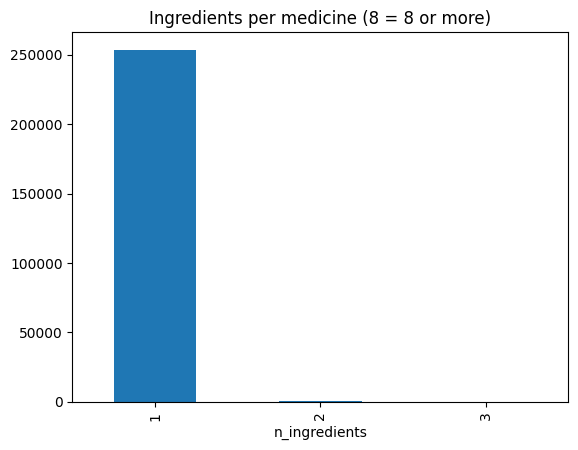

Unique ingredients: 1588


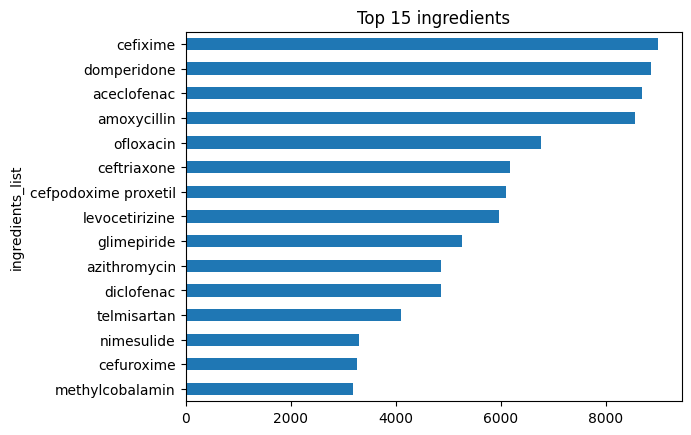

Medicines with a listed banned ingredient: 271
Medicines matching a prohibited FDC     : 0


In [72]:
# Single drugs vs combinations
medicine_df["n_ingredients"].clip(upper=8).value_counts().sort_index().plot(
    kind="bar", title="Ingredients per medicine (8 = 8 or more)")
plt.show()

# Most common ingredients
all_ing = medicine_df["ingredients_list"].explode().dropna()
print("Unique ingredients:", all_ing.nunique())
all_ing.value_counts().head(15).sort_values().plot(kind="barh", title="Top 15 ingredients")
plt.show()

# Overlap with banned list and prohibited FDCs (exact-name estimate)
banned_set = set(banned_df["drug_norm"].dropna()) - {""}
has_banned = medicine_df["ingredients_list"].apply(lambda L: any(i in banned_set for i in L))
print("Medicines with a listed banned ingredient:", has_banned.sum())

fdc_sets = [set(x) for x in fdc_df["fdc_ingredients"] if len(x) > 1]
has_fdc = medicine_df["ingredients_list"].apply(lambda L: any(f <= set(L) for f in fdc_sets))
print("Medicines matching a prohibited FDC     :", has_fdc.sum())

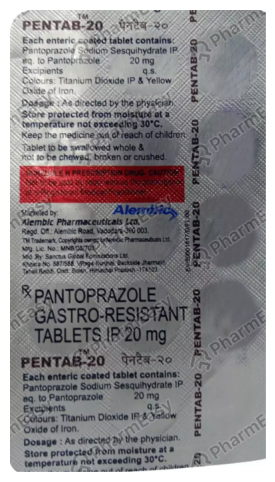

Medicine name (from label) : PENTAB, CONS, XPANTOPRAZ
Matched in master          : Pentab 40 Tablet; Pentab-D Tablet
Ingredients (master record) : pantoprazole
Also seen on label         : pantoprazole


KeyError: 'ban_set'

In [73]:
import difflib

_STOP = {"TABLET", "TABLETS", "CAPSULE", "CAPSULES", "EACH", "COATED", "ENTERIC", "STORE", "KEEP",
         "COLOURS", "EXCIPIENTS", "PROTECTED", "TEMPERATURE", "EXCEEDING", "PHYSICIAN",
         "SWALLOWED", "CONTAINS", "MEDICINE", "CHILDREN", "TITANIUM", "DIOXIDE", "OXIDE",
         "YELLOW", "BATCH", "PRICE", "LIMITED", "PHARMA", "MANUFACTURED"}

_names_l  = medicine_df[MED_NAME].astype(str).str.lower()
_ing_vocab = sorted({w for L in medicine_df["ingredients_list"] for ing in L
                     for w in ing.split() if len(w) >= 7})

def _brands(text):
    words = re.findall(r"\b[A-Z]{4,}\b", text)
    return [w for w in dict.fromkeys(words) if w not in _STOP]

def _label_ingredients(text):
    found = set()
    for tok in set(re.findall(r"[a-z]{7,}", text.lower())):
        if tok in _ing_vocab:
            found.add(tok)
        else:
            close = difflib.get_close_matches(tok, _ing_vocab, n=1, cutoff=0.88)
            if close:
                found.add(close[0])
    return sorted(found)

def _fmt(flags):
    seen, out = set(), []
    for f in flags:
        rec = f.get("record", {})
        key = (f["item"], rec.get("Notification_Number"))
        if key not in seen:
            seen.add(key)
            out.append(f"{f['item']}  ({rec.get('Notification_Number', '-')}, {rec.get('Notification_Date', '-')})")
    return out

def identify_medicine(image_path, n_matches=2):
    text = ocr_multi(image_path, show=True)
    brands = _brands(text)
    label_ings = _label_ingredients(text)

    # match label brand words to master medicine names
    matched = []
    for b in brands:
        hits = medicine_df[_names_l.str.startswith(b.lower())]
        matched += [r for _, r in hits.head(n_matches).iterrows()]
        if matched:
            break

    print("=" * 60)
    print("Medicine name (from label) :", ", ".join(brands[:3]) or "not read")
    if matched:
        print("Matched in master          :", "; ".join(r[MED_NAME] for r in matched))
    else:
        print("Matched in master          : not found")

    # ingredients: master record if matched, otherwise what OCR read from the label
    ings = sorted(set(matched[0]["ingredients_list"])) if matched else label_ings
    source = "master record" if matched else "read from label by OCR"
    print(f"Ingredients ({source}) :", ", ".join(ings) or "not read")
    if matched and label_ings:
        print("Also seen on label         :", ", ".join(label_ings))

    check_ings = sorted(set(ings) | set(label_ings))
    banned = _fmt(check_banned(check_ings))
    fdc    = _fmt(check_fdc(check_ings))

    print("Prohibited FDC             :", ("YES\n    - " + "\n    - ".join(fdc)) if fdc else "No")
    print("Banned                     :", ("YES\n    - " + "\n    - ".join(banned)) if banned else "No")

    if banned or fdc:
        print("Result                     : ⚠️ BANNED / PROHIBITED. Do not use. Ask a doctor or pharmacist.")
    elif not check_ings:
        print("Result                     : ❓ Could not read ingredients. Try a clearer photo.")
    else:
        print("Result                     : ✅ Not found in banned/prohibited lists (not a guarantee of safety)")

identify_medicine("F.png")

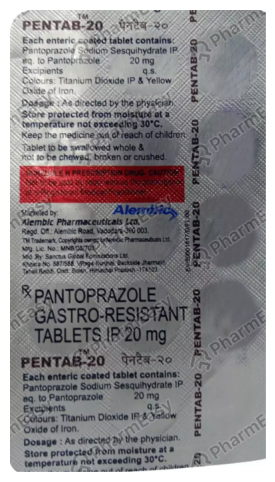

Medicine    : Pentab 40 Tablet
Ingredients : pantoprazole
------------------------------------------------------------
Banned      : NO
Prohibited  : NO
------------------------------------------------------------
RESULT      : SAFE as per banned/prohibited lists.
              (Check expiry and take only as your doctor advises.)


In [ ]:
# 1) Banned entries: use whichever text lists MORE ingredients
def build_ban_set(row):
    a = split_ingredients(row.get("Ingredients_Normalized"))
    b = split_ingredients(row.get(BAN_COL))
    return a if len(a) >= len(b) else b

banned_df["ban_set"] = banned_df.apply(build_ban_set, axis=1)

# 2) Banned only if ALL ingredients of the entry are present in the medicine
def check_banned(ingredients):
    flags, seen = [], set()
    ing_set = set(ingredients)
    for _, h in banned_df.iterrows():
        b = h["ban_set"]
        if not b:
            continue
        if all(any(names_match(x, i) for i in ing_set) for x in b):
            key = (" + ".join(b), h.get("Notification_Number"))
            if key in seen:
                continue
            seen.add(key)
            rec = h.drop(["drug_norm", "ban_set"], errors="ignore").to_dict()
            flags.append({"type": "BANNED_OR_RESTRICTED" if len(b) == 1 else "BANNED_COMBINATION",
                          "item": " + ".join(b), "record": rec})
    return flags

# 3) Final report
def quick_check(image_path, allergies=None):
    text = ocr_multi(image_path, show=True)
    brands = _brands(text)
    label_ings = _label_ingredients(text)

    matched = []
    for b in brands:
        hits = medicine_df[_names_l.str.startswith(b.lower())]
        matched += [r for _, r in hits.head(2).iterrows()]
        if matched:
            break

    # master ingredients win; OCR words are used only if the brand is not in the master
    check_ings = sorted(set(matched[0]["ingredients_list"])) if matched else label_ings
    banned = _fmt(check_banned(check_ings))
    fdc    = _fmt(check_fdc(check_ings))

    print("=" * 60)
    print("Medicine    :", matched[0][MED_NAME] if matched else (", ".join(brands[:2]) or "not read"))
    print("Ingredients :", ", ".join(check_ings) or "not read")
    print("-" * 60)
    print("Banned      :", "YES (BANNED)" if banned else "NO")
    for b in banned:
        print("    -", b)
    print("Prohibited  :", "YES (PROHIBITED)" if fdc else "NO")
    for f in fdc:
        print("    -", f)

    allergy_hit = False
    if allergies:
        print("-" * 60)
        for level, a, detail in allergen_check(check_ings, text, allergies):
            word = {"❌": "CONTAINS", "⚠️": "POSSIBLE", "➖": "NOT FOUND"}.get(level, "")
            print(f"Allergy     : {a} -> {word}: {detail}")
            allergy_hit |= level in ("❌", "⚠️")

    print("-" * 60)
    if banned or fdc:
        print("RESULT      : NOT SAFE. Banned/prohibited. Do not use.")
    elif allergy_hit:
        print("RESULT      : ALLERGY WARNING. Ask a doctor or pharmacist first.")
    elif not check_ings:
        print("RESULT      : Could not read ingredients. Try a clearer photo.")
    else:
        print("RESULT      : SAFE as per banned/prohibited lists.")
        print("              (Check expiry and take only as your doctor advises.)")

quick_check("F.png")

In [ ]:
def make_pipe(clf):
    return Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5),
                                  max_features=50000, sublinear_tf=True)),
        ("clf", clf),
    ])
 
candidates = {
    "RandomForest": make_pipe(RandomForestClassifier(
        n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)),
    # LinearSVC = linear-kernel SVM; the only SVM that scales to ~250k text rows.
    "SVM (LinearSVC)": make_pipe(LinearSVC(class_weight="balanced", C=1.0, random_state=RANDOM_STATE)),
}
 
# Quick 5-fold comparison on a stratified sample of the TRAIN set only.
n = min(CV_SAMPLE, len(X_train))
Xs, _, ys, _ = train_test_split(X_train, y_train, train_size=n, stratify=y_train, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
 
scores = {}
for name, pipe in candidates.items():
    res = cross_validate(pipe, Xs, ys, cv=cv, n_jobs=1,
                         scoring=["f1", "precision", "recall", "accuracy"])
    scores[name] = {k: res[f"test_{k}"].mean() for k in ["f1", "precision", "recall", "accuracy"]}
    print(f"\n{name}")
    for k, v in scores[name].items():
        print(f"  {k:9s}: {v:.4f}")
 
best_name = max(scores, key=lambda k: scores[k]["f1"])
print(f"\n>>> Best model by F1: {best_name}")


In [ ]:
best = candidates[best_name]
best.fit(X_train, y_train)

In [ ]:
pred = best.predict(X_test)
print("\n=== Final test results ===")
print(classification_report(y_test, pred, target_names=["No ban found", "Banned"], digits=4))
print("Confusion matrix:\n", confusion_matrix(y_test, pred))
print("Test F1:", round(f1_score(y_test, pred), 4))

In [74]:
import pickle

bundle = {
    "medicine_df": medicine_df,   # includes ingredients_list
    "banned_df":   banned_df,     # includes ban_set
    "fdc_df":      fdc_df,        # includes fdc_ingredients
}

with open("medicine_safety_data.pkl", "wb") as f:
    pickle.dump(bundle, f, protocol=pickle.HIGHEST_PROTOCOL)

print("Saved: medicine_safety_data.pkl")

Saved: medicine_safety_data.pkl
